# Machine Learning-Based Cardiometabolic Risk Stratification Using Population Health Data: An Explainable Clinical Decision Support System

## Notebook 4: SHAP Explainability, Fairness Analysis and Framingham Comparison

**Student Name:** Vanshika Karnwal | Student ID: 201957572  
**Supervisor:** Dr Baoru Huang  
**Module:** COMP702 Dissertation | University of Liverpool  
**Dataset:** NHANES 2017-March 2020 Pre-Pandemic  
**Source:** https://wwwn.cdc.gov/nchs/nhanes/Default.aspx

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
from sklearn.preprocessing import LabelEncoder

print("Libraries loaded")

Libraries loaded


In [2]:
DISSERTATION_PATH = r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION'

# Load model and scaler
model = joblib.load(f'{DISSERTATION_PATH}\\xgb_model_v2.pkl')
scaler = joblib.load(f'{DISSERTATION_PATH}\\scaler_v2.pkl')

with open(f'{DISSERTATION_PATH}\\feature_names_v2.json') as f:
    feature_names = json.load(f)

# Load dataset
df = pd.read_csv(r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION\DATASETS\nhanes_final_dataset_dissertation.csv')

print("Model loaded")
print("Dataset shape:", df.shape)
print("Features:", feature_names)

Model loaded
Dataset shape: (3528, 22)
Features: ['Age', 'Gender', 'Diastolic_BP', 'Waist_Circumference', 'Total_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'LDL_Cholesterol', 'Smoking_Status', 'Total_PA_Minutes', 'Sedentary_Hours', 'Uric_Acid', 'GGT', 'eGFR', 'Race_Non-Hispanic Asian', 'Race_Non-Hispanic Black', 'Race_Non-Hispanic White', 'Race_Other Hispanic', 'Race_Other/Multi-Racial']


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# Recreate X and y exactly as in Notebook 3
X = df.drop(columns=['Risk_category', 'SEQN',
                      'HbA1c', 'Fasting_Glucose',
                      'Systolic_BP', 'BMI',
                      'Creatinine', 'eGFR_Stage'],
            errors='ignore')

y = df['Risk_category']

X['Gender'] = X['Gender'].map({'Male': 0, 'Female': 1})
X['Smoking_Status'] = X['Smoking_Status'].map({'Never': 0, 'Former': 1, 'Current': 2})
X = pd.get_dummies(X, columns=['Race'], drop_first=True)

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

X_test_scaled = scaler.transform(X_test)

print("Test set recreated")
print("Test shape:", X_test_scaled.shape)

Test set recreated
Test shape: (706, 19)


## 1. SHAP Explainability Analysis

SHAP (SHapley Additive exPlanations) values quantify the contribution 
of each feature to individual predictions. A TreeExplainer is used 
for XGBoost, providing exact SHAP values efficiently.

In [4]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_scaled)

print("SHAP values shape:", np.array(shap_values).shape)
print("Shape interpretation: (participants, features, classes)")
print("Classes: High=0, Low=1, Moderate=2")

SHAP values shape: (706, 19, 3)
Shape interpretation: (participants, features, classes)
Classes: High=0, Low=1, Moderate=2


### 1.1 Global Feature Importance - High Risk Class

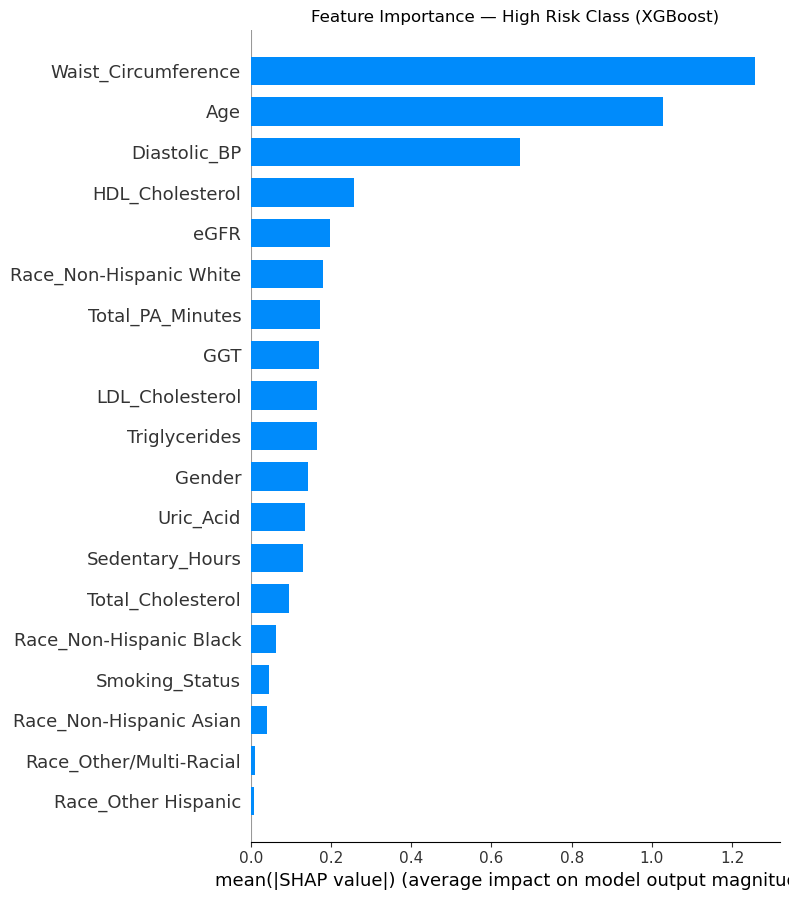

In [5]:
plt.figure()
shap.summary_plot(shap_values[:, :, 0], X_test_scaled,
                  feature_names=feature_names,
                  plot_type='bar', show=False)
plt.title('Feature Importance — High Risk Class (XGBoost)')
plt.tight_layout()
plt.savefig('shap_high_risk_bar.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.2 SHAP Beeswarm Plot - High Risk Class
Shows direction and magnitude of each feature's influence.
- Red dots = high feature values
- Blue dots = low feature values  
- Right of zero = pushes toward High risk
- Left of zero = pushes away from High risk

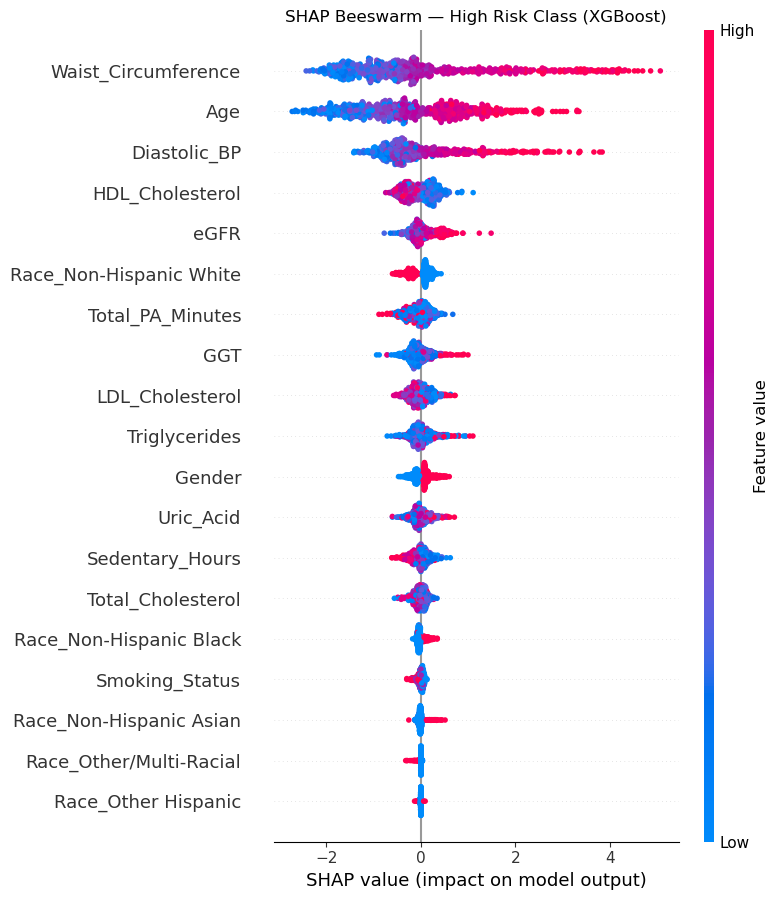

In [6]:
plt.figure()
shap.summary_plot(shap_values[:, :, 0], X_test_scaled,
                  feature_names=feature_names, show=False)
plt.title('SHAP Beeswarm — High Risk Class (XGBoost)')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

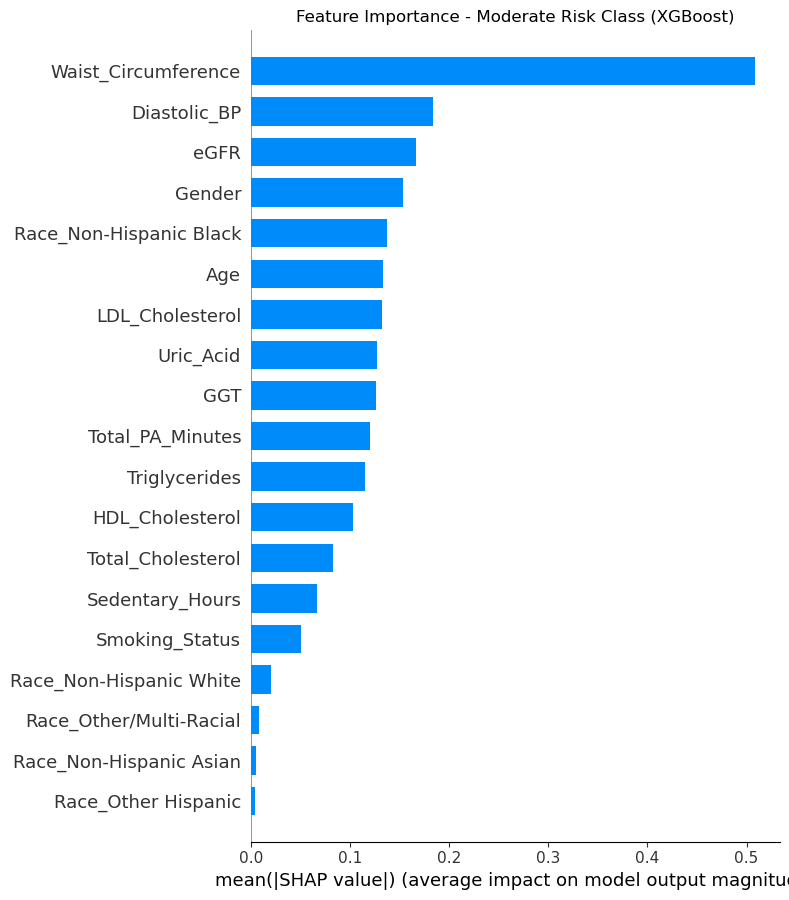

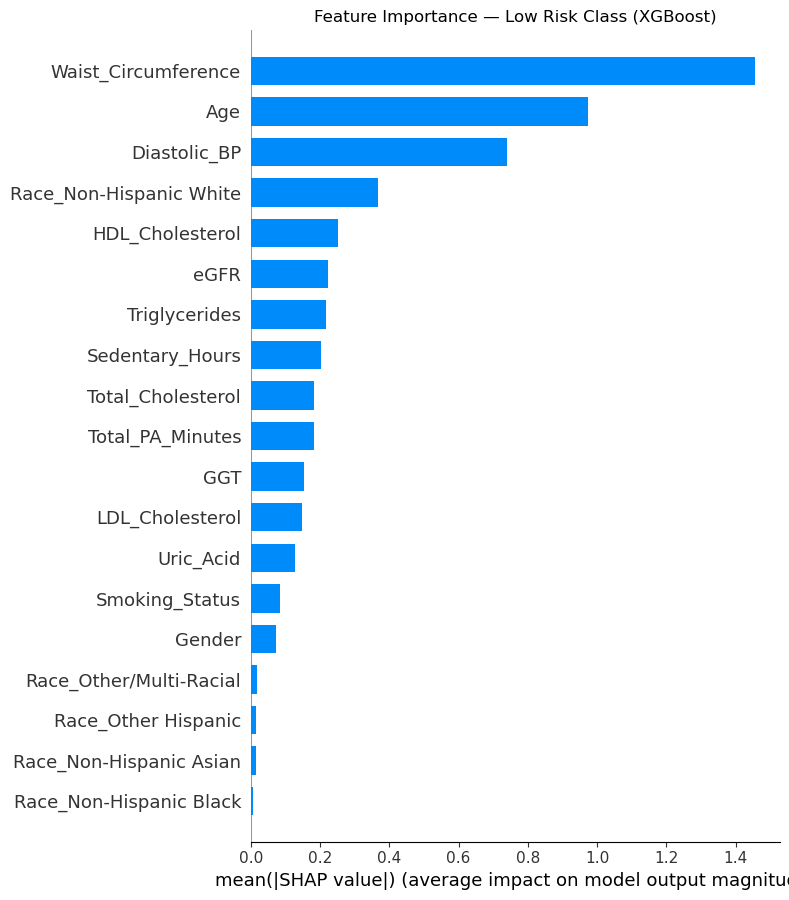

In [7]:
# Moderate risk
plt.figure()
shap.summary_plot(shap_values[:, :, 2], X_test_scaled,
                  feature_names=feature_names,
                  plot_type='bar', show=False)
plt.title('Feature Importance - Moderate Risk Class (XGBoost)')
plt.tight_layout()
plt.savefig('shap_moderate_risk_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# Low risk
plt.figure()
shap.summary_plot(shap_values[:, :, 1], X_test_scaled,
                  feature_names=feature_names,
                  plot_type='bar', show=False)
plt.title('Feature Importance — Low Risk Class (XGBoost)')
plt.tight_layout()
plt.savefig('shap_low_risk_bar.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Framingham Risk Score Comparison

The Framingham Risk Score (D'Agostino et al., 2008) estimates 
10-year cardiovascular disease risk. It is used here as a clinical 
validation benchmark to contextualise the ML model predictions.

In [9]:
def framingham_risk_score(row):
    """
    Framingham 10-year CVD Risk Score
    Reference: D'Agostino et al., Circulation 2008
    """
    age = row['Age']
    gender = row['Gender']
    total_chol = row['Total_Cholesterol']
    hdl_chol = row['HDL_Cholesterol']
    sbp = row['Systolic_BP']
    smoking = 1 if row['Smoking_Status'] == 'Current' else 0
    diabetes = 1 if row['HbA1c'] >= 6.5 else 0

    if gender == 'Male':
        log_score = (3.06117 * np.log(age) +
                     1.12370 * np.log(total_chol) -
                     0.93263 * np.log(hdl_chol) +
                     1.93303 * np.log(sbp) +
                     0.65451 * smoking +
                     0.57367 * diabetes - 23.9802)
        risk = 1 - (0.88936 ** np.exp(log_score))
    else:
        log_score = (2.32888 * np.log(age) +
                     1.20904 * np.log(total_chol) -
                     0.70833 * np.log(hdl_chol) +
                     2.76157 * np.log(sbp) +
                     0.52873 * smoking +
                     0.69154 * diabetes - 26.1931)
        risk = 1 - (0.94833 ** np.exp(log_score))

    return round(risk * 100, 1)

def framingham_category(score):
    if score < 10: return 'Low'
    elif score < 20: return 'Moderate'
    else: return 'High'

df['Framingham_Score'] = df.apply(framingham_risk_score, axis=1)
df['Framingham_Category'] = df['Framingham_Score'].apply(framingham_category)

print("Framingham Score Distribution:")
print(df['Framingham_Category'].value_counts())
print("\nML Risk Distribution:")
print(df['Risk_category'].value_counts())

Framingham Score Distribution:
Framingham_Category
Low         2262
Moderate     723
High         543
Name: count, dtype: int64

ML Risk Distribution:
Risk_category
High        1470
Moderate    1391
Low          667
Name: count, dtype: int64


In [10]:
kappa = cohen_kappa_score(df['Risk_category'], df['Framingham_Category'])
print(f"Cohen's Kappa: {kappa:.3f}")
print("\nAgreement Table:")
crosstab = pd.crosstab(df['Risk_category'], df['Framingham_Category'],
                        rownames=['ML Model'], colnames=['Framingham'])
print(crosstab)

Cohen's Kappa: 0.149

Agreement Table:
Framingham  High   Low  Moderate
ML Model                        
High         429   634       407
Low            5   621        41
Moderate     109  1007       275


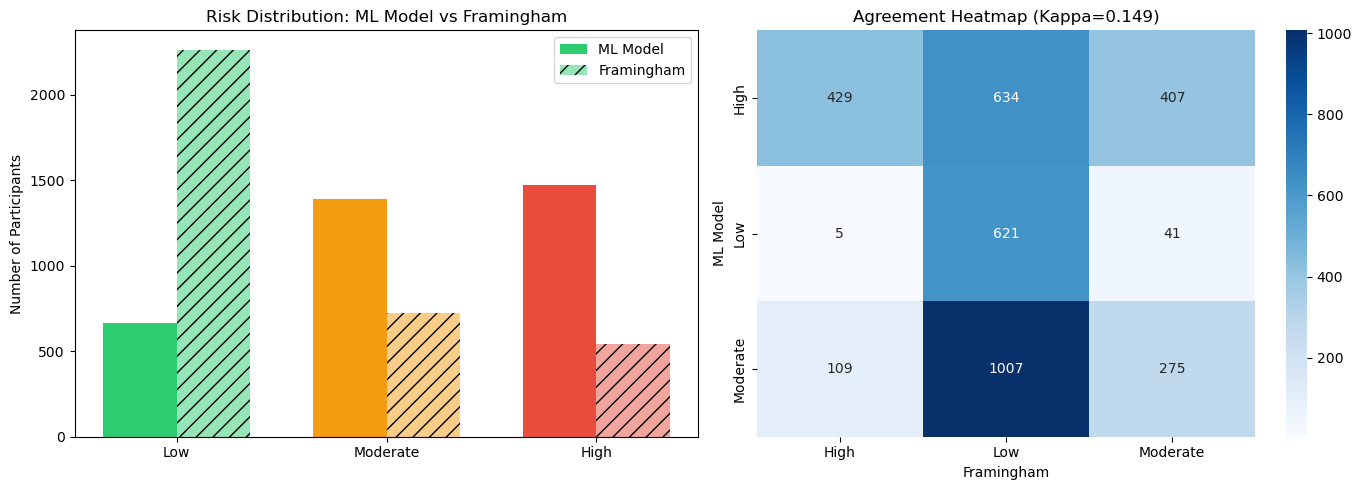

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = ['Low', 'Moderate', 'High']
colors = ['#2ecc71', '#f39c12', '#e74c3c']

ml_counts = [df['Risk_category'].value_counts()[r] for r in order]
fram_counts = [df['Framingham_Category'].value_counts()[r] for r in order]

x = np.arange(len(order))
width = 0.35

axes[0].bar(x - width/2, ml_counts, width, label='ML Model', color=colors)
axes[0].bar(x + width/2, fram_counts, width, label='Framingham',
            color=colors, alpha=0.5, hatch='//')
axes[0].set_xticks(x)
axes[0].set_xticklabels(order)
axes[0].set_title('Risk Distribution: ML Model vs Framingham')
axes[0].set_ylabel('Number of Participants')
axes[0].legend()

sns.heatmap(crosstab, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title(f'Agreement Heatmap (Kappa={kappa:.3f})')

plt.tight_layout()
plt.savefig('framingham_comparison.png', dpi=150)
plt.show()

## 3. Fairness Analysis

Model performance is evaluated across demographic subgroups to assess 
equity of predictions - essential for responsible clinical AI deployment 
(Obermeyer et al., 2019).

In [12]:
y_pred = model.predict(X_test_scaled)

# Recreate test demographics
test_idx = X_test.index
fairness_df = df.loc[test_idx, ['Gender', 'Race']].copy()
fairness_df['Actual'] = le.inverse_transform(y_test)
fairness_df['Predicted'] = le.inverse_transform(y_pred)

print("Fairness dataframe:", fairness_df.shape)
print(fairness_df.head())

Fairness dataframe: (706, 4)
      Gender                Race    Actual Predicted
3224  Female  Non-Hispanic Black       Low       Low
3335    Male  Non-Hispanic White  Moderate      High
651   Female    Mexican American       Low       Low
1725    Male  Non-Hispanic White      High  Moderate
3280  Female  Non-Hispanic Asian      High      High


In [13]:
print("FAIRNESS ANALYSIS BY GENDER")
print("="*50)

gender_results = []
for gender in ['Male', 'Female']:
    subset = fairness_df[fairness_df['Gender'] == gender]
    accuracy = (subset['Actual'] == subset['Predicted']).mean()
    from sklearn.metrics import f1_score
    f1 = f1_score(subset['Actual'], subset['Predicted'],
                  average='macro', zero_division=0)
    gender_results.append({'Gender': gender, 'N': len(subset),
                           'Accuracy': round(accuracy, 3),
                           'Macro_F1': round(f1, 3)})
    print(f"\n{gender} (n={len(subset)}):")
    print(classification_report(subset['Actual'], subset['Predicted'],
                                zero_division=0))

print(pd.DataFrame(gender_results).to_string(index=False))

FAIRNESS ANALYSIS BY GENDER

Male (n=321):
              precision    recall  f1-score   support

        High       0.75      0.66      0.70       131
         Low       0.56      0.53      0.54        47
    Moderate       0.62      0.69      0.65       143

    accuracy                           0.66       321
   macro avg       0.64      0.63      0.63       321
weighted avg       0.66      0.66      0.66       321


Female (n=385):
              precision    recall  f1-score   support

        High       0.77      0.77      0.77       163
         Low       0.67      0.64      0.65        87
    Moderate       0.55      0.57      0.56       135

    accuracy                           0.67       385
   macro avg       0.66      0.66      0.66       385
weighted avg       0.67      0.67      0.67       385

Gender   N  Accuracy  Macro_F1
  Male 321     0.657     0.634
Female 385     0.670     0.662


In [14]:
print("FAIRNESS ANALYSIS BY RACE")
print("="*50)

race_results = []
for race in fairness_df['Race'].unique():
    subset = fairness_df[fairness_df['Race'] == race]
    if len(subset) < 20:
        continue
    accuracy = (subset['Actual'] == subset['Predicted']).mean()
    f1 = f1_score(subset['Actual'], subset['Predicted'],
                  average='macro', zero_division=0)
    race_results.append({'Race': race, 'N': len(subset),
                         'Accuracy': round(accuracy, 3),
                         'Macro_F1': round(f1, 3)})

race_df = pd.DataFrame(race_results).sort_values('Accuracy', ascending=False)
print(race_df.to_string(index=False))

FAIRNESS ANALYSIS BY RACE
              Race   N  Accuracy  Macro_F1
Non-Hispanic Asian  83     0.723     0.721
Non-Hispanic Black 187     0.674     0.651
Non-Hispanic White 255     0.655     0.643
    Other Hispanic  60     0.650     0.655
  Mexican American  88     0.648     0.642
Other/Multi-Racial  33     0.606     0.564


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender
genders = [r['Gender'] for r in gender_results]
g_acc = [r['Accuracy'] for r in gender_results]
g_f1 = [r['Macro_F1'] for r in gender_results]

x = np.arange(len(genders))
width = 0.35
axes[0].bar(x - width/2, g_acc, width, label='Accuracy', color='#3498db')
axes[0].bar(x + width/2, g_f1, width, label='Macro F1', color='#e74c3c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(genders)
axes[0].set_ylim(0, 1)
axes[0].set_title('Fairness by Gender')
axes[0].set_ylabel('Score')
axes[0].legend()
axes[0].axhline(y=0.66, color='black', linestyle='--', alpha=0.5, label='Overall')

# Race
races = race_df['Race'].tolist()
r_acc = race_df['Accuracy'].tolist()
r_f1 = race_df['Macro_F1'].tolist()

x2 = np.arange(len(races))
short_races = ['NH White', 'Mex Am', 'NH Black', 'NH Asian', 'Oth Hisp', 'Other']
axes[1].bar(x2 - width/2, r_acc, width, label='Accuracy', color='#3498db')
axes[1].bar(x2 + width/2, r_f1, width, label='Macro F1', color='#e74c3c')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(short_races[:len(races)], fontsize=8)
axes[1].set_ylim(0, 1)
axes[1].set_title('Fairness by Race/Ethnicity')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].axhline(y=0.66, color='black', linestyle='--', alpha=0.5)

plt.suptitle('Model Fairness Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fairness_analysis.png', dpi=150)
plt.show()